# 02 - Classification Results
Loads and displays the real classification results produced by `src/classification.py` (MSI status + ferroptosis risk-group, 4 models each). Run `python main.py` first.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200)

results = pd.read_csv('../results/classification_results.csv')
results[['experiment','model','accuracy','precision','recall','f1','roc_auc','pr_auc']].round(3)

,experiment,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,exp1_msi_raw_genes,LogisticRegression,0.849,0.500,0.889,0.640,0.917,0.677
1,exp1_msi_raw_genes,RandomForest,0.815,0.433,0.722,0.542,0.902,0.604
2,exp1_msi_raw_genes,SVM,0.765,0.375,0.833,0.517,0.904,0.713
3,exp1_msi_raw_genes,XGBoost,0.840,0.400,0.111,0.174,0.861,0.475
4,exp2_msi_engineered,LogisticRegression,0.639,0.234,0.611,0.338,0.651,0.265
5,exp2_msi_engineered,RandomForest,0.672,0.267,0.667,0.381,0.649,0.253
6,exp2_msi_engineered,SVM,0.613,0.220,0.611,0.324,0.633,0.225
7,exp2_msi_engineered,XGBoost,0.849,0.000,0.000,0.000,0.652,0.234
8,exp3_riskgroup_raw_genes,LogisticRegression,0.975,0.967,0.983,0.975,0.995,0.995
9,exp3_riskgroup_raw_genes,RandomForest,0.814,0.785,0.864,0.823,0.902,0.892


## Experiment 1: MSI classification, raw ferroptosis genes (primary, non-circular result)

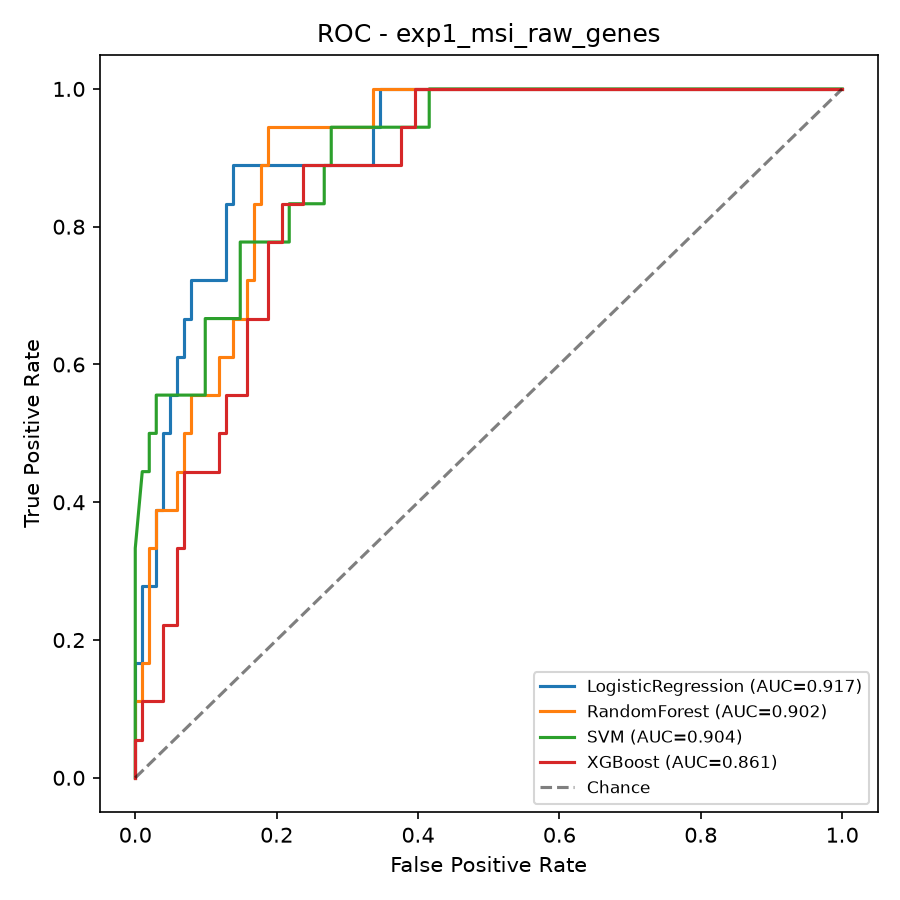

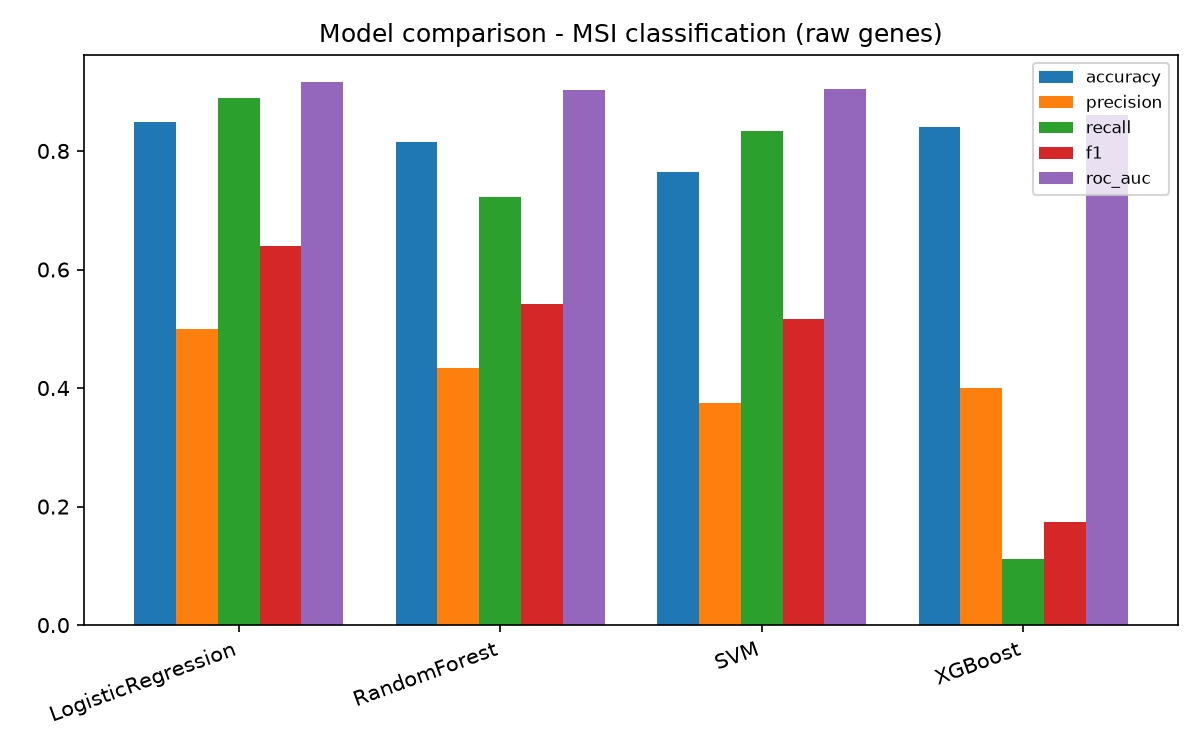

In [2]:
display(Image('../figures/roc_curve_exp1_msi_raw_genes.png'))
display(Image('../figures/model_comparison_msi_classification.png'))

## Experiment 2 vs 1: does the engineered signature score help?

In [3]:
best_by_exp = results.loc[results.groupby('experiment')['roc_auc'].idxmax()]
best_by_exp[['experiment','model','roc_auc']]

,experiment,model,roc_auc
0,exp1_msi_raw_genes,LogisticRegression,0.916942
7,exp2_msi_engineered,XGBoost,0.651815
8,exp3_riskgroup_raw_genes,LogisticRegression,0.994829


Raw genes (exp1) clearly outperform the compact engineered score (exp2) — see `RESULTS.md` for discussion. Experiment 3 (ferroptosis risk group) is a circular, exploratory task — see `docs/LIMITATIONS.md` before over-interpreting its high scores.

## Interpretability: top ferroptosis genes for MSI classification

,gene,perm_importance_mean,perm_importance_std
0,NFS1,0.185992,0.049842
1,HOXC11,0.040997,0.013561
2,SLC7A11,0.019362,0.009566
3,SLC2A3,0.014686,0.009786
4,TFAP2C,0.013770,0.008516
5,ATG7,0.010689,0.005986
6,HAMP,0.006436,0.003766
7,ZFP69B,0.005996,0.003341
8,TXNIP,0.004859,0.007459
9,NOS2,0.004749,0.003326


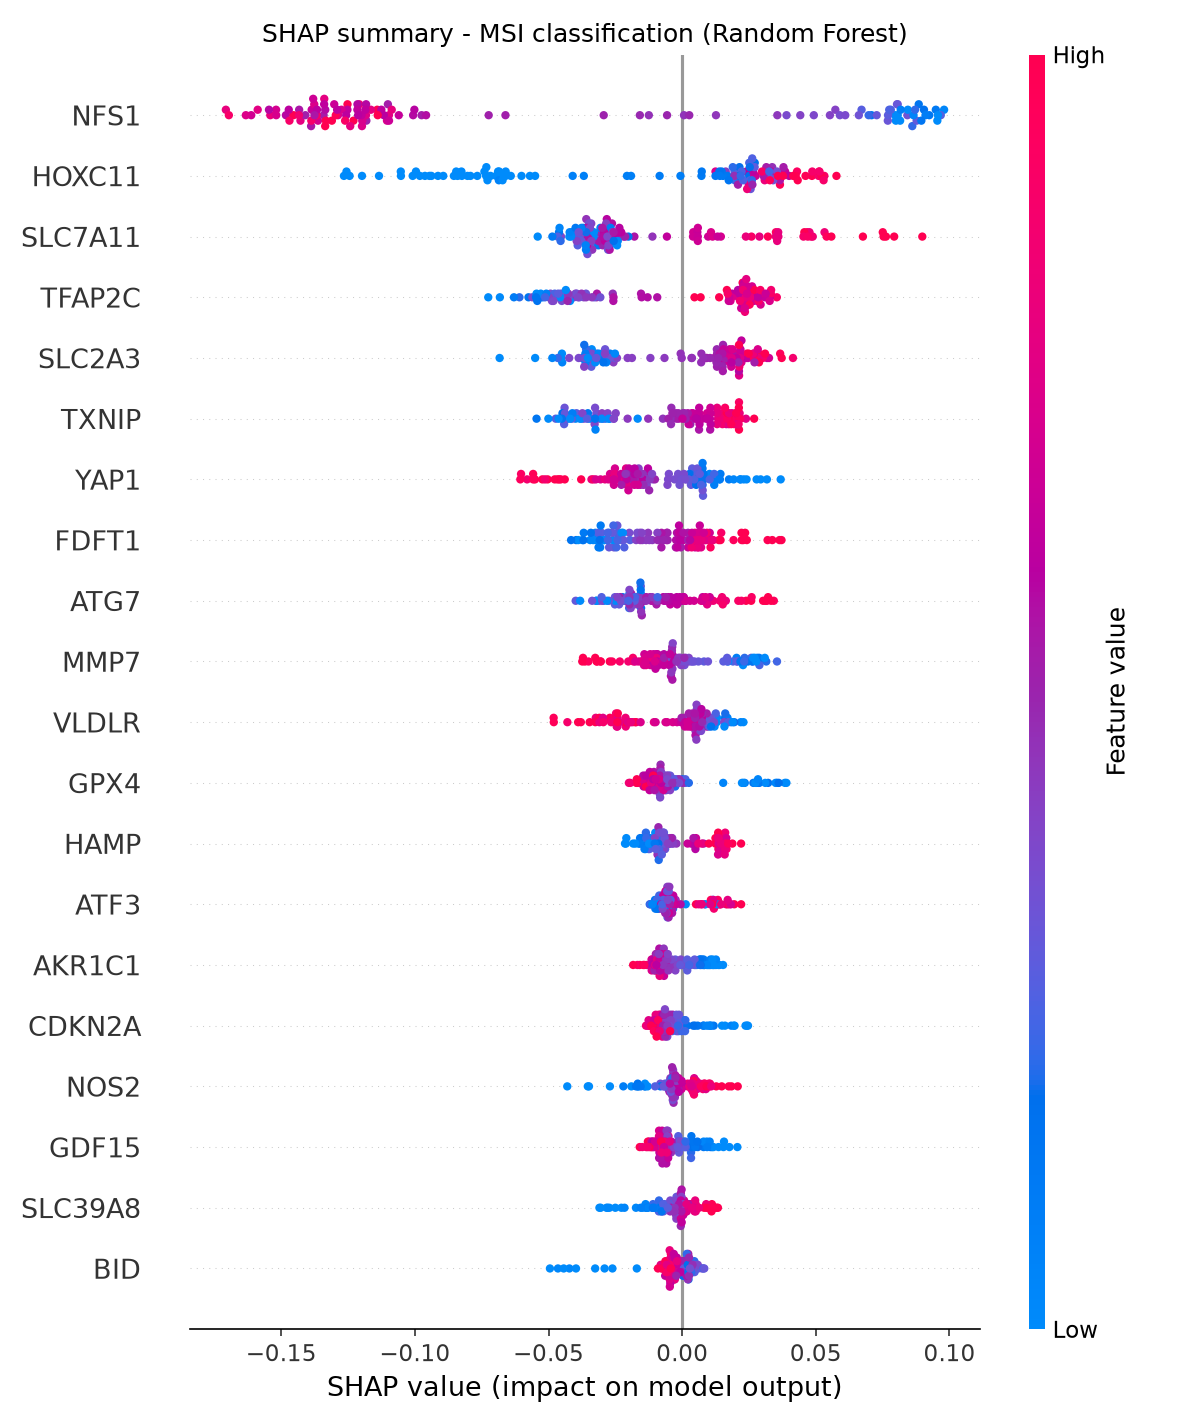

In [4]:
perm = pd.read_csv('../results/feature_importance_classification_permutation.csv')
display(perm.head(10))
display(Image('../figures/shap_summary_classification.png'))